___
<h1> Machine Learning </h1>
<h2> Systems Engineering and Computer Technologies / Engenharia de Sistemas e Tecnologias Informáticas
(LESTI)</h2>
<h3> Instituto Superior de Engenharia / Universidade do Algarve </h3>

[LESTI](https://ise.ualg.pt/curso/1941) / [ISE](https://ise.ualg.pt) / [UAlg](https://www.ualg.pt)

Pedro J. S. Cardoso (pcardoso@ualg.pt)

___

# $k$-Nearest Neighbors (kNN): Regression

In [1]:
from sklearn.model_selection import train_test_split
# !pip3 install mglearn

import matplotlib.pyplot as plt
#import mglearn.plots

from sklearn.neighbors import KNeighborsRegressor
import numpy as np

## k-Neighbors Regression

There is also a regression variant of the k-nearest neighbors algorithm. Again, let’s start by using a single nearest neighbor, this time using the wave dataset. 

The prediction using a single neighbor (1-NN) is just the target value of the nearest neighbor. When using multiple nearest neighbors for regression, the prediction is the average (or mean) of the relevant neighbors

In [2]:
np.random.seed(2)

n_samples = 50
a, b = -10, 10

# set of "x's"
timeline = np.linspace(a, b, n_samples).reshape(-1, 1)

# set a 'wave'
def make_wave(timeline):
    return 10 * np.cos(timeline) + 5 * np.random.rand(len(timeline))

wave = make_wave(timeline.T[0])

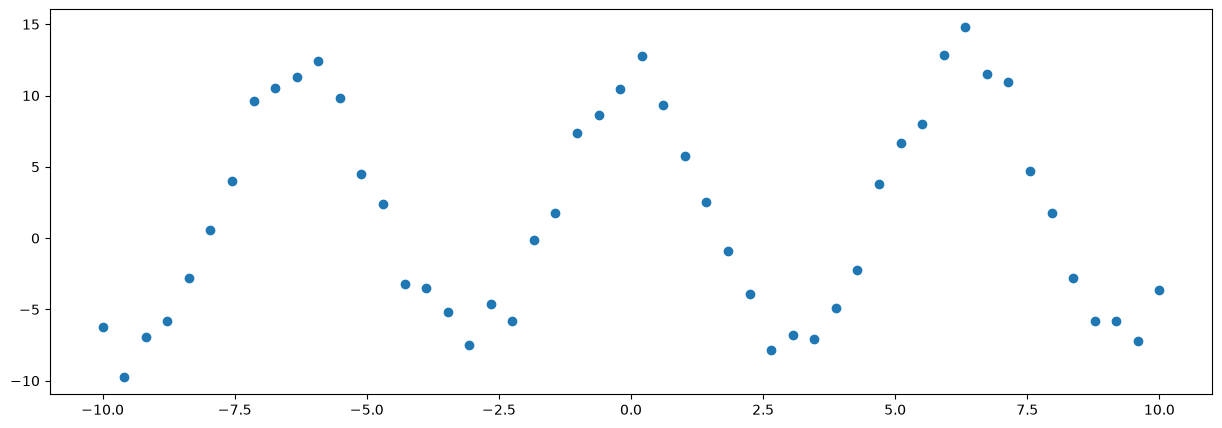

In [3]:
fig = plt.figure(figsize=(15,5))
ax = fig.add_subplot(111)
ax.plot(timeline, wave, linestyle='None', marker='o')
plt.show()

As usual, split the test

In [4]:
x_train, x_test, y_train, y_test = train_test_split(timeline, wave, test_size=.1 )

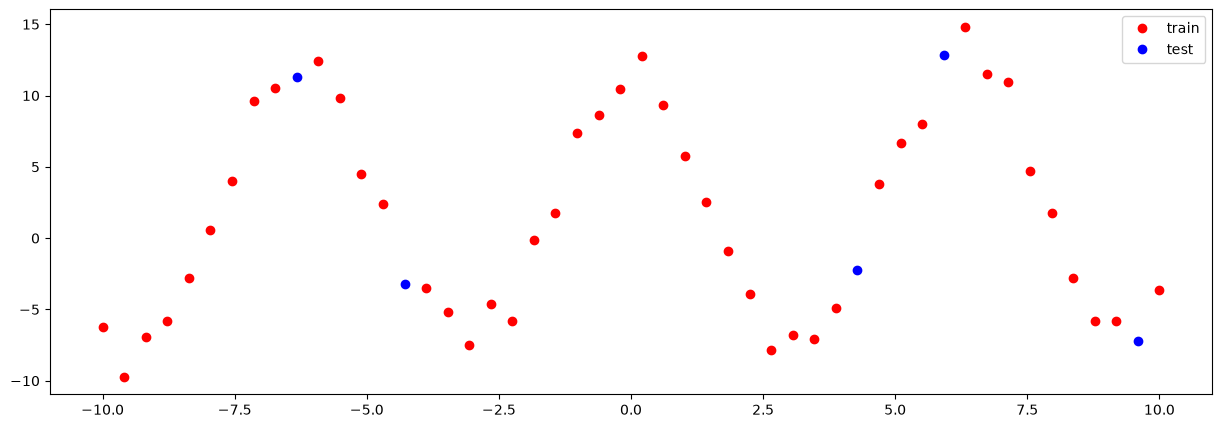

In [5]:
fig = plt.figure(figsize=(15,5))
ax = fig.add_subplot(111)
ax.plot(x_train, y_train, linestyle="none", marker='o', c="red")
ax.plot(x_test, y_test, linestyle="none", marker='o', c="blue")
ax.legend(["train", "test"])
plt.show()

and then train the model

In [6]:
knr = KNeighborsRegressor(
        n_neighbors=3, 
        weights='distance' # 'uniform' or 'distance'
)

knr.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


And now the predictions

In [7]:
print(x_test)
print(y_test)
print(knr.predict(x_test))

[[ 5.91836735]
 [ 4.28571429]
 [-6.32653061]
 [-4.28571429]
 [ 9.59183673]]
[12.84564898 -2.20399589 11.32474377 -3.21625982 -7.1827602 ]
[11.41285906  0.89869281 11.10213475  0.45334676 -4.93628885]


And we can see compute the errors

In [8]:
y_pred = knr.predict(x_test)

delta = y_pred - y_test
delta

array([-1.43278992,  3.1026887 , -0.22260902,  3.66960658,  2.24647134])

And the score (coefficient of determination $R^2$ of the prediction) is

In [9]:
knr.score(x_test, y_test)

0.9092639026125272

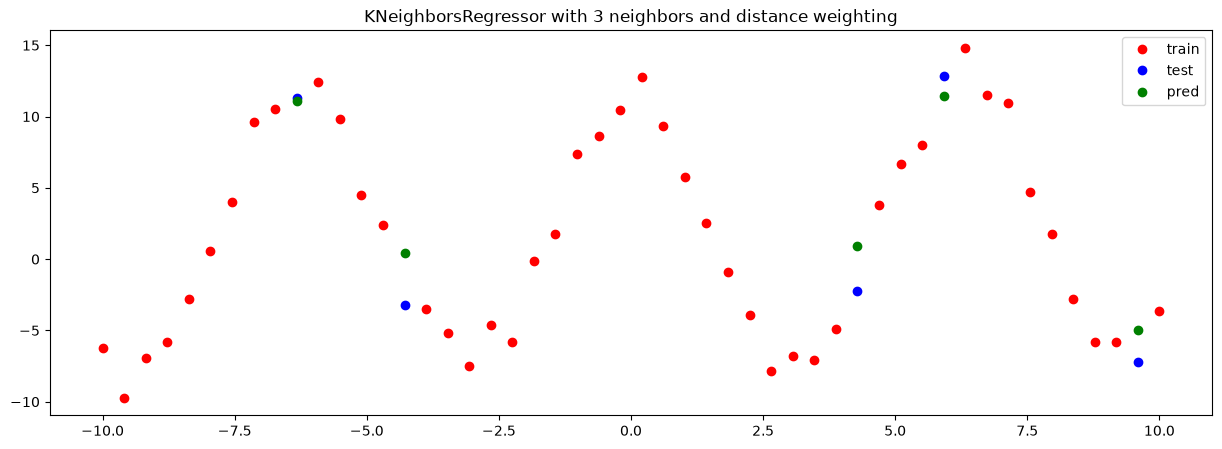

In [10]:
fig = plt.figure(figsize=(15,5))
ax = fig.add_subplot(111)
ax.plot(x_train, y_train, linestyle="none", marker='o', c="red")
ax.plot(x_test, y_test, linestyle="none", marker='o', c="blue")
ax.plot(x_test, y_pred, linestyle="none", marker='o', c="green")
ax.legend(["train", "test", "pred"])
ax.set_title("KNeighborsRegressor with 3 neighbors and distance weighting")
plt.show()

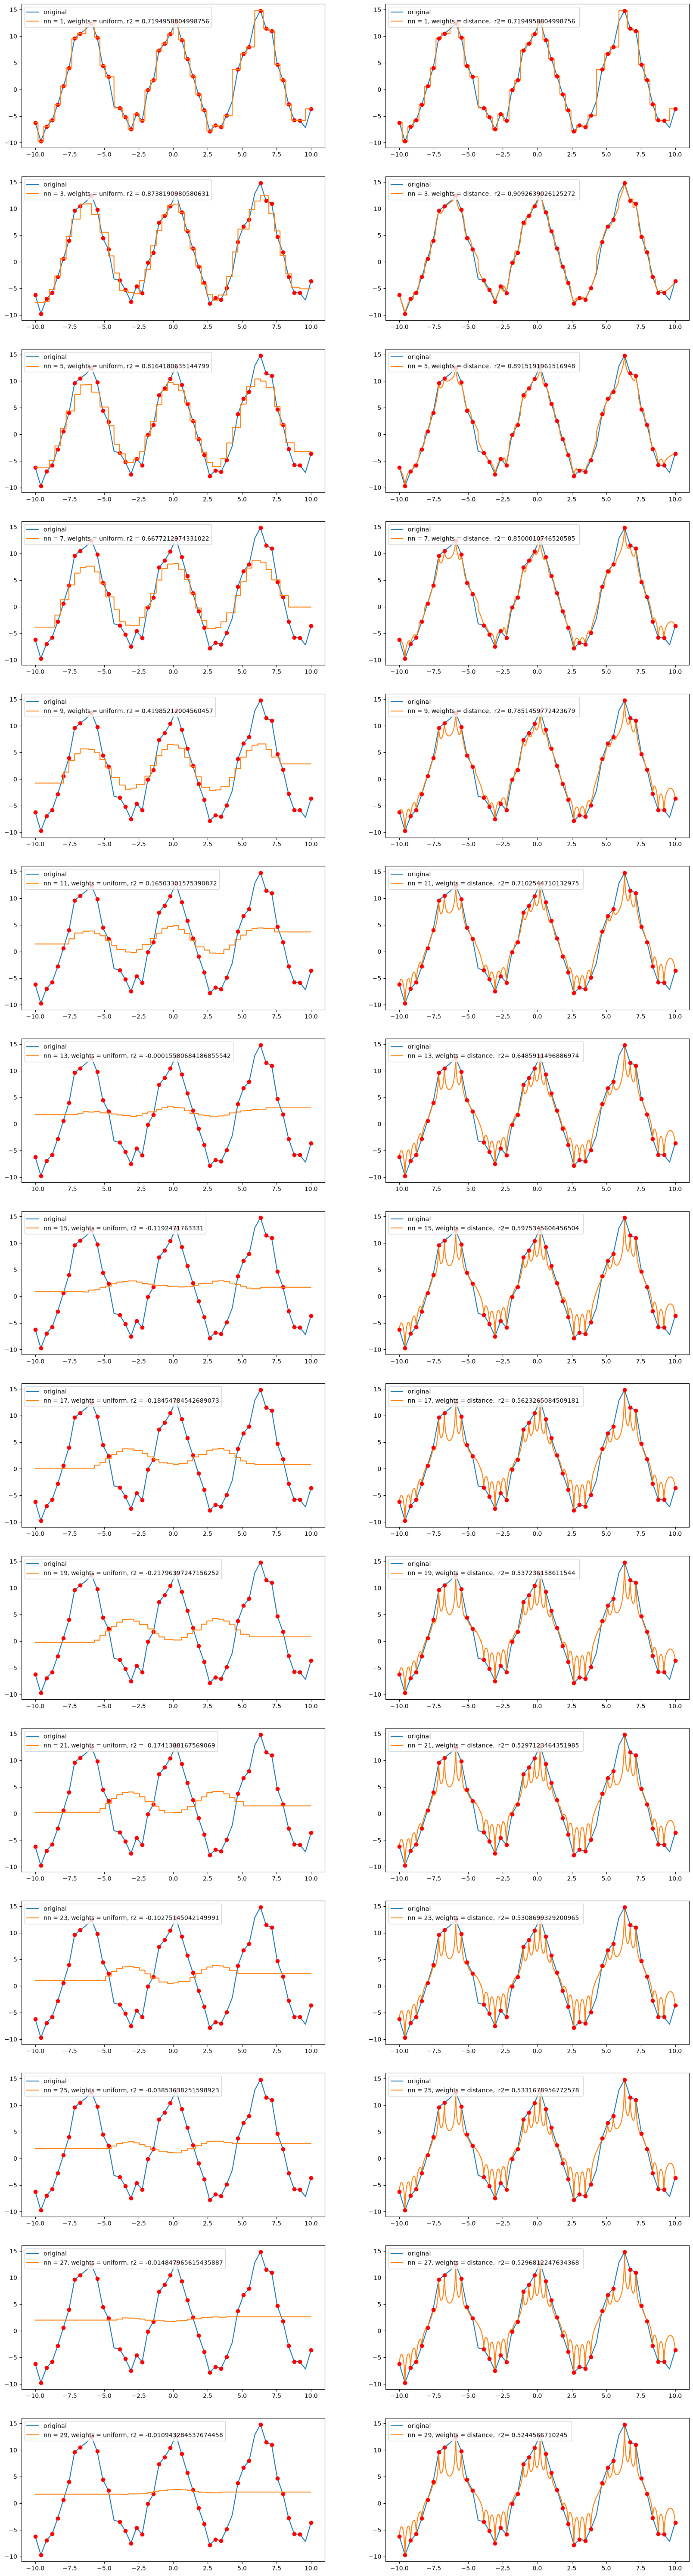

In [11]:
X = np.arange(a, b, .01).reshape(-1, 1)

K = 30
fig = plt.figure(figsize=(10 * 2, 5 * K))

im_idx = 0

for nn in range(1, K, 2):
    #  weights='uniform'
    # ‘uniform’ : uniform weights. All points in each neighborhood are weighted equally.
    knr = KNeighborsRegressor(n_neighbors=nn, weights='uniform').fit(x_train, y_train)
    y = knr.predict(X)

    im_idx += 1
    ax = fig.add_subplot(K - 1, 2, im_idx)
    ax.plot(timeline, wave, label='original')
    ax.plot(x_train, y_train, linestyle="none", marker='o', c="red")
    ax.plot(X, y, label=f'nn = {nn}, weights = uniform, r2 = {knr.score(x_test, y_test)}')
    ax.legend()

    # weights='distance'
    # ‘distance’ : weight points by the inverse of their distance. In this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.
    knr = KNeighborsRegressor(n_neighbors=nn, weights='distance').fit(x_train, y_train)
    y = knr.predict(X)
    
    im_idx += 1
    ax = fig.add_subplot(K - 1, 2, im_idx)
    ax.plot(timeline, wave, label='original')
    ax.plot(X, y, label=f'nn = {nn}, weights = distance,  r2= {knr.score(x_test, y_test)} ')
    ax.plot(x_train, y_train, linestyle="none", marker='o', c="red")
    ax.legend()
    
plt.show()

Let us see how it behaves outside the samples

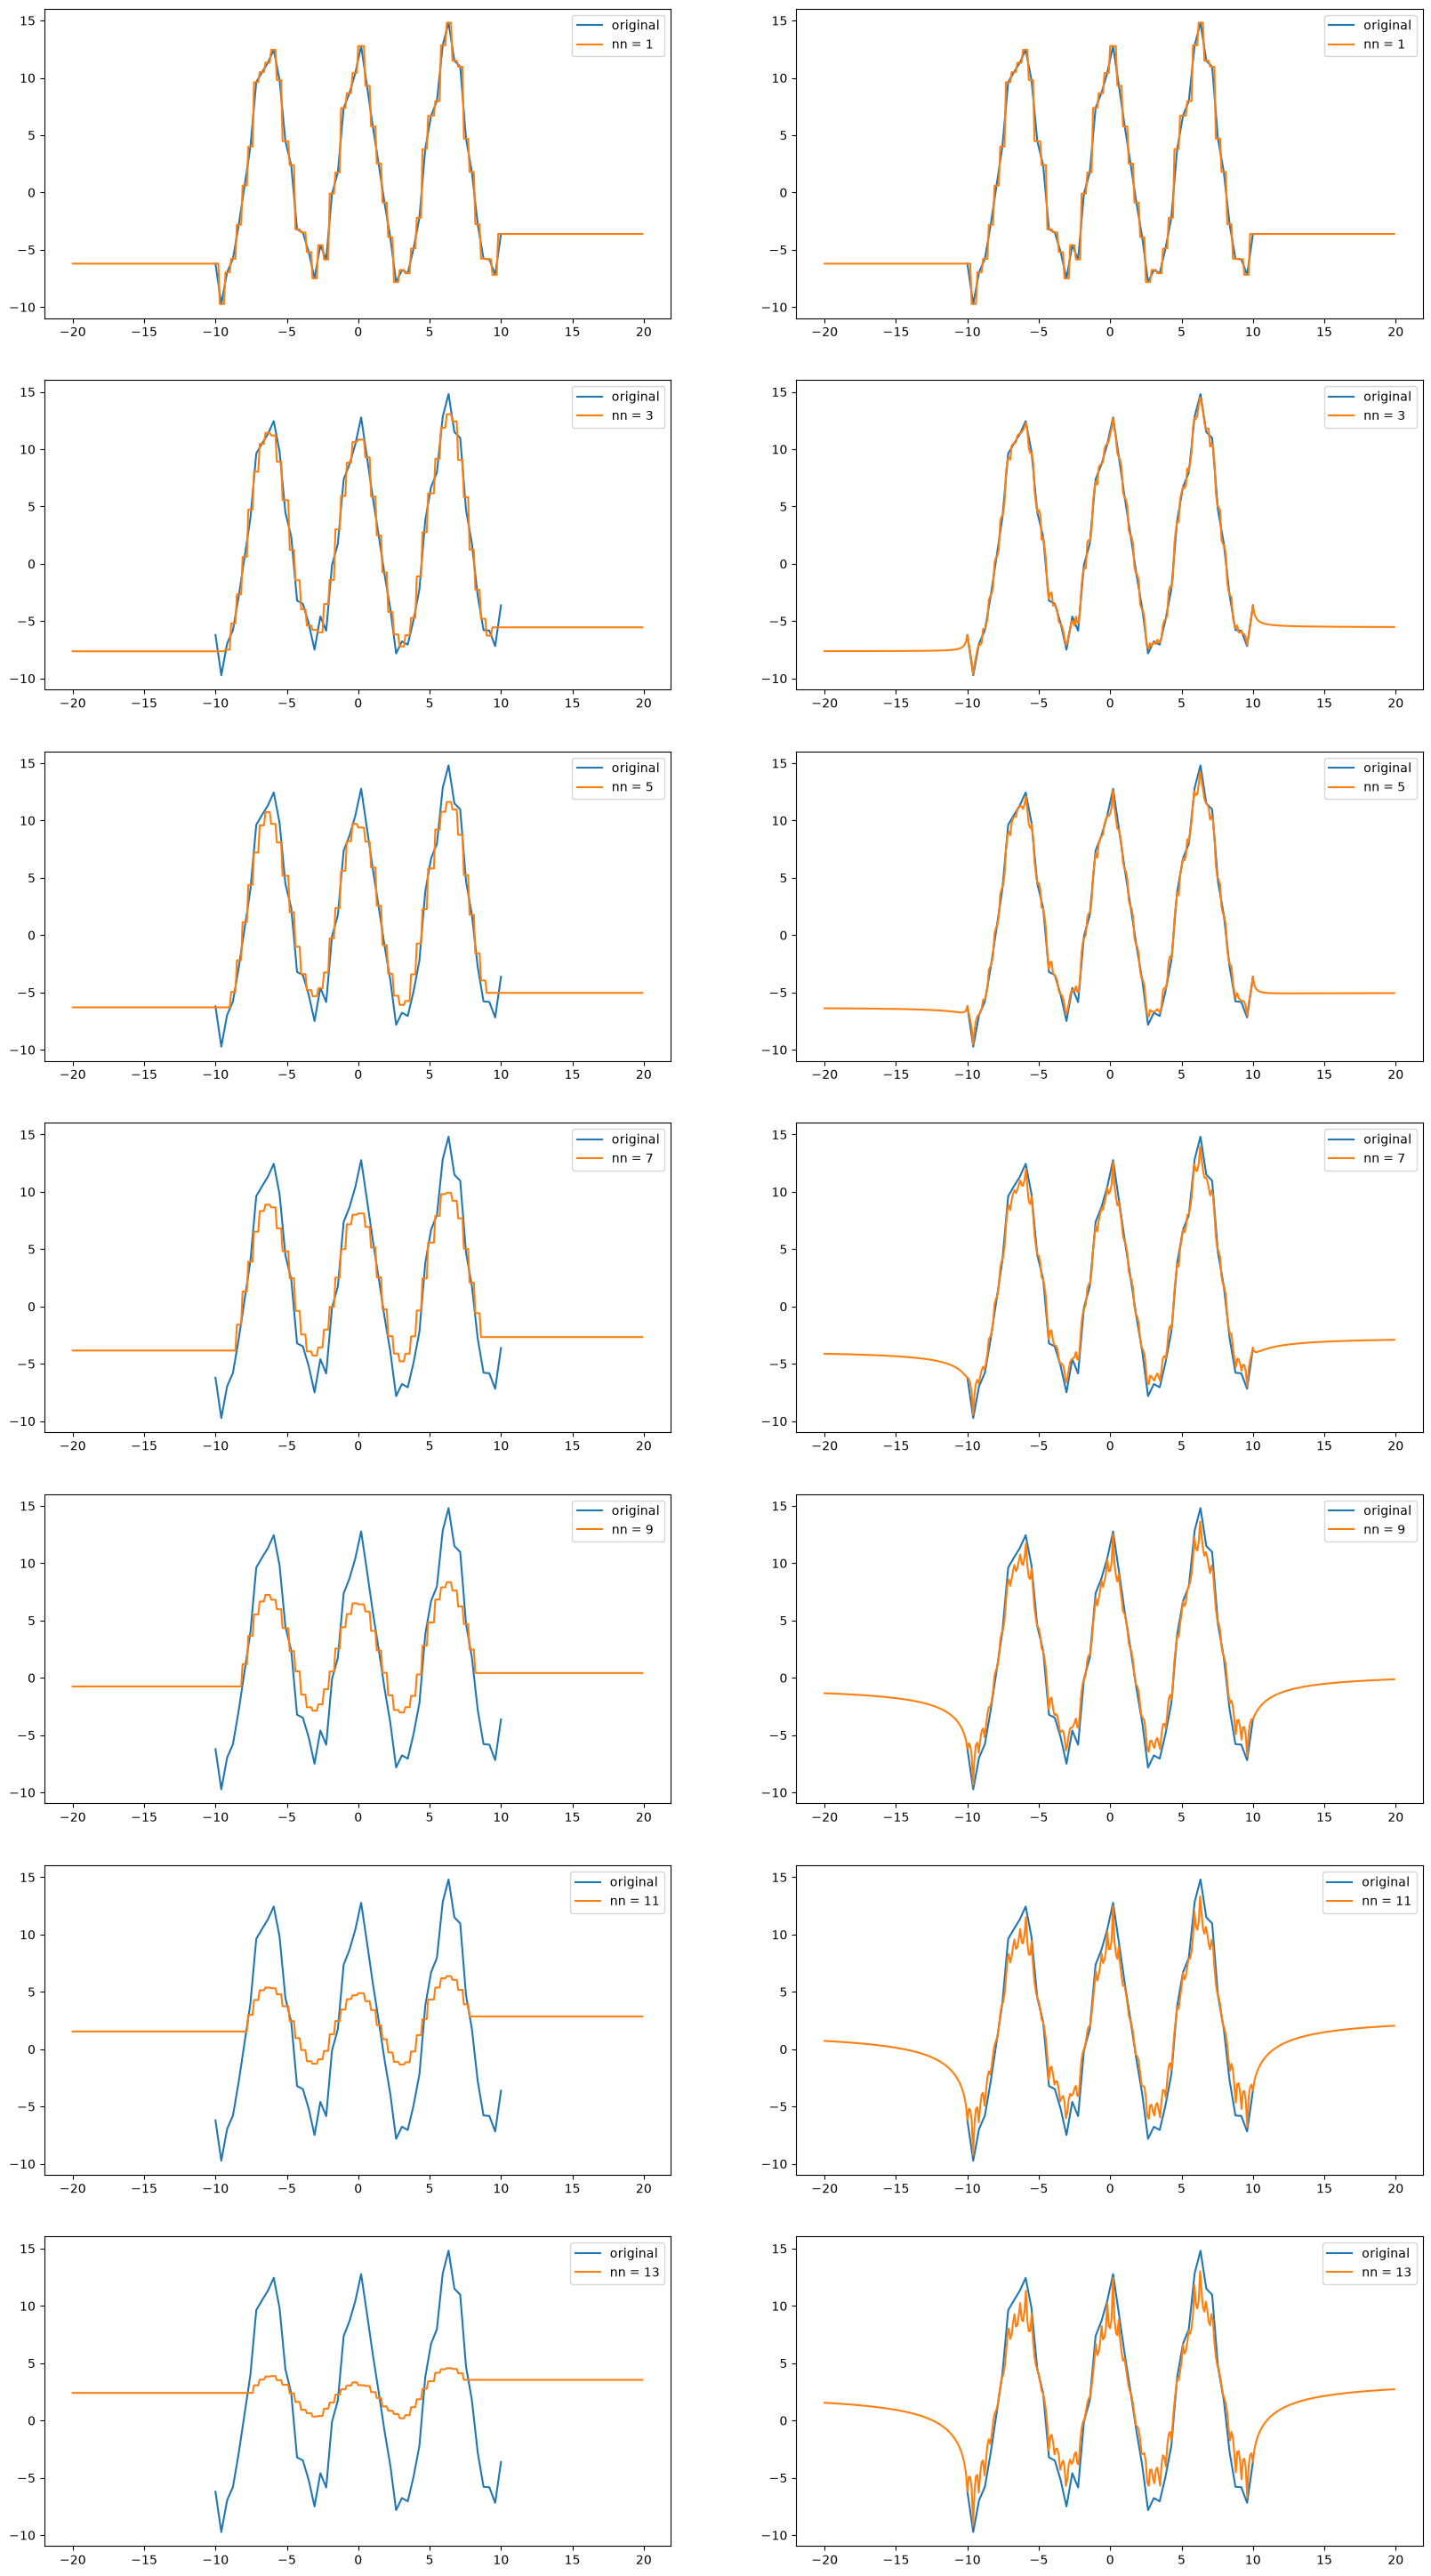

In [12]:
# supposing a<0
X = np.arange(2 * a, 2 * b, .1).reshape(-1, 1)

K = 15
fig = plt.figure(figsize=(10 * 2, 5 * K))

im_idx = 0

for nn in range(1, K, 2):
    #  weights='uniform'
    # ‘uniform’ : uniform weights. All points in each neighborhood are weighted equally.
    knr = KNeighborsRegressor(n_neighbors=nn, weights='uniform').fit(timeline, wave)
    y = knr.predict(X)

    im_idx += 1
    ax = fig.add_subplot(K - 1, 2, im_idx)
    ax.plot(timeline, wave, label='original')
    ax.plot(X, y, label='nn = {}'.format(nn))
    ax.legend()

    # weights='distance'
    # ‘distance’ : weight points by the inverse of their distance. In this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.
    knr = KNeighborsRegressor(n_neighbors=nn, weights='distance').fit(timeline, wave)
    y = knr.predict(X)
    
    im_idx += 1
    ax = fig.add_subplot(K - 1, 2, im_idx)
    ax.plot(timeline, wave, label='original')
    ax.plot(X, y, label='nn = {}'.format(nn))
    ax.legend()
    
plt.show()

## Example: Grid search with cross-validation on Wine Quality using k-NN regression

We will predict the numeric `quality` rating of red wine from its physicochemical measurements. The data is split into training and test sets; five-fold cross-validation on the training set selects the hyperparameters, and the held-out test set is used only for the final evaluation. The grid explores the number of neighbors, voting weights, distance metric, Minkowski distance power, search algorithm, and leaf size for tree-based searches. Scaling is part of the pipeline, so it is fitted separately within each cross-validation fold. Since the search uses negative MAE as its scoring metric, `best_score_` is negated to report MAE; test R² is computed separately.

In [13]:
import pandas as pd
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

wine = pd.read_csv('../week.06/Exercises/winequality-red.csv', sep=';')
X = wine.drop(columns='quality')
y = wine['quality']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f'Train: {len(y_train)} | Test: {len(y_test)}')

knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor())
])

tree_params = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15, 20],
    'knn__weights': ['uniform', 'distance'],
    'knn__algorithm': ['auto', 'ball_tree', 'kd_tree'],
    'knn__leaf_size': [15, 30, 45]
}

param_grid = [
    {
        **tree_params,
        'knn__metric': ['minkowski'],
        'knn__p': [1, 2]
    },
    {
        **tree_params,
        'knn__metric': ['chebyshev'],
    },
    {
        'knn__n_neighbors': [3, 5, 7, 9, 11, 15, 20],
        'knn__weights': ['uniform', 'distance'],
        'knn__metric': ['minkowski'],
        'knn__p': [1, 2],
        'knn__algorithm': ['brute']
    },
    {
        'knn__n_neighbors': [3, 5, 7, 9, 11, 15, 20],
        'knn__weights': ['uniform', 'distance'],
        'knn__metric': ['chebyshev'],
        'knn__algorithm': ['brute']
    }
]
 
wine_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=3
)

wine_search.fit(X_train, y_train)

print(f'Best parameters: {wine_search.best_params_}')
print(f'Mean cross-validation MAE: {-wine_search.best_score_:.3f}')
y_pred = wine_search.predict(X_test)
print(f'Test MAE: {mean_absolute_error(y_test, y_pred):.3f}')
print(f'Test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.3f}')
print(f'Test R²: {r2_score(y_test, y_pred):.3f}')

Train: 1279 | Test: 320
Fitting 5 folds for each of 420 candidates, totalling 2100 fits
[CV 3/5] END knn__algorithm=auto, knn__leaf_size=15, knn__metric=minkowski, knn__n_neighbors=3, knn__p=1, knn__weights=distance;, score=-0.469 total time=   0.0s
[CV 3/5] END knn__algorithm=auto, knn__leaf_size=15, knn__metric=minkowski, knn__n_neighbors=3, knn__p=1, knn__weights=uniform;, score=-0.555 total time=   0.0s
[CV 4/5] END knn__algorithm=auto, knn__leaf_size=15, knn__metric=minkowski, knn__n_neighbors=3, knn__p=1, knn__weights=uniform;, score=-0.499 total time=   0.0s
[CV 1/5] END knn__algorithm=auto, knn__leaf_size=15, knn__metric=minkowski, knn__n_neighbors=3, knn__p=1, knn__weights=uniform;, score=-0.471 total time=   0.0s
[CV 1/5] END knn__algorithm=auto, knn__leaf_size=15, knn__metric=minkowski, knn__n_neighbors=3, knn__p=2, knn__weights=distance;, score=-0.401 total time=   0.0s
[CV 5/5] END knn__algorithm=auto, knn__leaf_size=15, knn__metric=minkowski, knn__n_neighbors=3, knn__p=1,

## Faster alternative: Randomized Search

The exhaustive grid evaluates every parameter combination (420 candidates, or 2,100 fits with five-fold cross-validation). `RandomizedSearchCV` samples a fixed budget of 50 candidates instead (250 fits), trading exhaustive coverage for a much smaller search. It uses the same training data, folds, and MAE objective; the test set remains reserved for final evaluation. Run the grid-search cell above first.

In [14]:
from sklearn.model_selection import ParameterGrid, RandomizedSearchCV

n_iter = 50
random_search = RandomizedSearchCV(
    estimator=knn_pipeline,
    param_distributions=param_grid,
    n_iter=n_iter,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)
random_search.fit(X_train, y_train)

total_candidates = len(ParameterGrid(param_grid))
print(f'Full grid: {total_candidates} candidates, {total_candidates * 5} CV fits')
print(f'Random search: {n_iter} candidates, {n_iter * 5} CV fits')
print(f'CV fits reduced by {100 * (1 - n_iter / total_candidates):.1f}%')
print(f'Best parameters: {random_search.best_params_}')
print(f'Mean cross-validation MAE: {-random_search.best_score_:.3f}')

y_pred_random = random_search.predict(X_test)
print(f'Test MAE: {mean_absolute_error(y_test, y_pred_random):.3f}')
print(f'Test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_random)):.3f}')
print(f'Test R²: {r2_score(y_test, y_pred_random):.3f}')

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Full grid: 420 candidates, 2100 CV fits
Random search: 50 candidates, 250 CV fits
CV fits reduced by 88.1%
Best parameters: {'knn__weights': 'distance', 'knn__p': 1, 'knn__n_neighbors': 11, 'knn__metric': 'minkowski', 'knn__leaf_size': 45, 'knn__algorithm': 'auto'}
Mean cross-validation MAE: 0.425
Test MAE: 0.393
Test RMSE: 0.549
Test R²: 0.538
